# Module M4: Feature Engineering, Analysis & Model Training
**Dự án:** Virtual Try-On Platform  
**Mục tiêu:** 
1. Trích xuất các đặc trưng chuyên sâu về **Nhân trắc học (Anthropometry)** và **Tương tác Người $\leftrightarrow$ Áo (Garment-Body Interaction)**.
2. Trực quan hóa tương quan (Correlation & Distributions) để hiểu rõ dữ liệu.
3. Huấn luyện mô hình **Random Forest (Regressor & Classifier)** trên bộ đặc trưng mới.
4. Đánh giá chỉ số nghiệm thu ($\text{MAE} \le 5.0$, $\text{Macro-F1} \ge 0.75$) và phân tích Feature Importance.

In [2]:
import sys
from pathlib import Path

# Tự động tìm PROJECT_ROOT từ bất kỳ vị trí kernel nào
curr_path = Path(".").resolve()
while curr_path != curr_path.parent:
    if (curr_path / "pytest.ini").exists() or (curr_path / ".git").exists():
        PROJECT_ROOT = curr_path
        break
    curr_path = curr_path.parent
else:
    PROJECT_ROOT = Path(".").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
import joblib

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 1000)
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
print("[+] Môi trường sẵn sàng! PROJECT_ROOT:", PROJECT_ROOT)

[+] Môi trường sẵn sàng! PROJECT_ROOT: D:\Năm 4 - Kỳ 1\Project\virtual-tryon\virtual-try-on-platform


## 1. Nạp dữ liệu splits & Gán nhãn Fit Labeling (AI-03)
Nạp dữ liệu từ thư mục `ai/dataset/data/fit_30k/splits/` đã được chia chống rò rỉ (`GroupShuffleSplit`).

In [3]:
from ai.dataset.labeling.fit_labeler import assign_fit_labels, FIT_CLASSES
from ai.dataset.split import DEFAULT_SPLIT_DIR, run_pipeline

train_path = DEFAULT_SPLIT_DIR / "train.csv"
val_path = DEFAULT_SPLIT_DIR / "val.csv"
test_path = DEFAULT_SPLIT_DIR / "test.csv"

# Tự động chạy pipeline nếu chưa có splits
if not (train_path.exists() and test_path.exists()):
    print("[!] Chưa tìm thấy splits, đang tự động chạy split pipeline...")
    run_pipeline()

print(f"[*] Nạp dữ liệu từ: {DEFAULT_SPLIT_DIR}")
train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)
test_df = pd.read_csv(test_path)

# Gán nhãn Fit Labeling
train_df = assign_fit_labels(train_df)
val_df = assign_fit_labels(val_df)
test_df = assign_fit_labels(test_df)

print(f"[*] Train shape: {train_df.shape} | Val shape: {val_df.shape} | Test shape: {test_df.shape}")
print("[*] Phân phối Fit Class trên Train set:")
print(train_df["fit_class"].value_counts(normalize=True).apply(lambda x: f"{x:.2%}"))
train_df.head(3)

[*] Nạp dữ liệu từ: D:\Năm 4 - Kỳ 1\Project\virtual-tryon\virtual-try-on-platform\ai\dataset\data\fit_30k\splits
[*] Train shape: (21000, 15) | Val shape: (4500, 15) | Test shape: (4500, 15)
[*] Phân phối Fit Class trên Train set:
fit_class
Good         45.33%
Too Loose    34.53%
Too Tight    20.14%
Name: proportion, dtype: str


,id,cloth_path,person_path,target_path,body_bust,body_height,body_hips,body_waist,garment_bust,garment_length,garment_sleeve_length,size_label,bust_diff,fit_class,fit_score
0,fit_000001,images/cloth/fit_000001.jpg,images/person/fit_000001.jpg,images/target/fit_000001.jpg,108.177002,174.324997,109.658997,96.499901,124.403549,54.288181,17.441977,L,16.226547,Too Loose,77.501596
1,fit_000002,images/cloth/fit_000002.jpg,images/person/fit_000002.jpg,images/target/fit_000002.jpg,94.343903,184.343002,98.605202,76.634201,88.774071,45.227295,18.878109,M,-5.569832,Too Tight,30.581009
2,fit_000003,images/cloth/fit_000003.jpg,images/person/fit_000003.jpg,images/target/fit_000003.jpg,133.177002,169.867004,129.585007,125.571999,147.826477,73.092087,43.978596,XL,14.649475,Too Loose,80.971155


## 2. Feature Engineering: Trích xuất các Đặc trưng Nhân trắc học & Tương tác
Tạo ra 15 đặc trưng mô tả tương tác Người $\leftrightarrow$ Áo và tỷ lệ vóc dáng cơ thể.

In [4]:
def extract_fit_features(df: pd.DataFrame) -> pd.DataFrame:
    """Trích xuất 15 đặc trưng hình học & nhân trắc học từ số đo cơ thể và áo."""
    data = df.copy()
    
    # 1. Độ chênh lệch và tỷ lệ cử động (Ease Features)
    if "bust_diff" not in data.columns:
        data["bust_diff"] = data["garment_bust"] - data["body_bust"]
    
    data["ease_ratio"] = data["garment_bust"] / (data["body_bust"] + 1e-6)
    data["length_to_height"] = data["garment_length"] / (data["body_height"] + 1e-6)
    data["abs_optimal_delta"] = (data["bust_diff"] - 6.0).abs()
    data["is_negative_ease"] = (data["bust_diff"] < 2.0).astype(float)
    
    # 2. Tỷ lệ nhân trắc học cơ thể (Anthropometric Proportions)
    data["bust_to_waist"] = data["body_bust"] / (data["body_waist"] + 1e-6)
    data["bust_to_hip"] = data["body_bust"] / (data["body_hips"] + 1e-6)
    data["waist_to_hip"] = data["body_waist"] / (data["body_hips"] + 1e-6)
    data["body_frame_index"] = (data["body_bust"] + data["body_waist"] + data["body_hips"]) / (data["body_height"] + 1e-6)
    
    return data

FEATURE_COLS = [
    "body_bust", "body_height", "body_hips", "body_waist",
    "garment_bust", "garment_length",
    "bust_diff", "ease_ratio", "length_to_height", "abs_optimal_delta", "is_negative_ease",
    "bust_to_waist", "bust_to_hip", "waist_to_hip", "body_frame_index",
]

train_feat = extract_fit_features(train_df)
val_feat = extract_fit_features(val_df)
test_feat = extract_fit_features(test_df)

print(f"[+] Đã trích xuất {len(FEATURE_COLS)} đặc trưng thành công!")
print("[*] Kiểm tra giá trị thiếu (NaN):", train_feat[FEATURE_COLS].isna().sum().sum())
train_feat[FEATURE_COLS].describe().round(2).T[["mean", "std", "min", "50%", "max"]]

[+] Đã trích xuất 15 đặc trưng thành công!
[*] Kiểm tra giá trị thiếu (NaN): 0


,mean,std,min,50%,max
body_bust,105.12,10.73,82.72,103.35,147.04
body_height,172.11,8.77,149.77,171.33,195.72
body_hips,106.68,9.60,87.55,105.16,152.27
body_waist,91.40,13.96,61.20,89.22,142.31
garment_bust,114.49,13.04,88.69,113.14,183.81
garment_length,53.89,8.67,32.26,52.09,94.51
bust_diff,9.37,10.79,-14.97,6.54,86.66
ease_ratio,1.09,0.11,0.86,1.06,1.92
length_to_height,0.31,0.05,0.18,0.30,0.56
abs_optimal_delta,8.25,7.73,0.00,6.16,80.66


## 3. Trực quan hóa Tương quan (Correlation & Distributions)

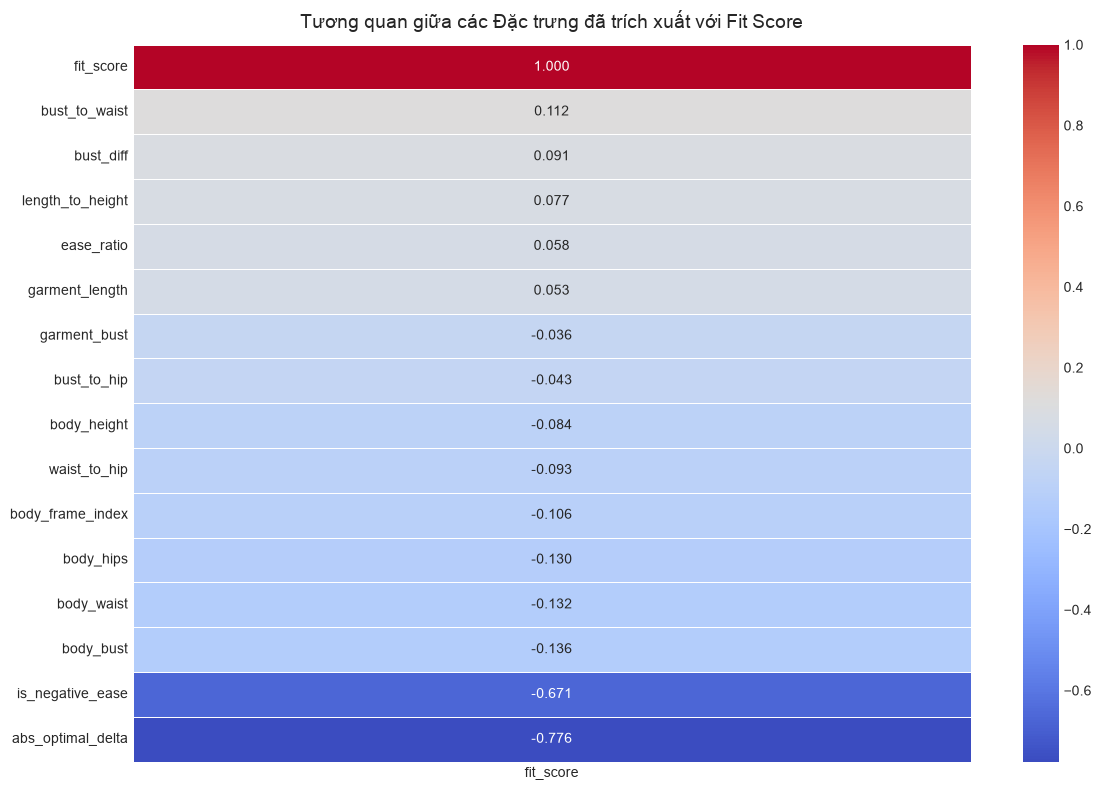

In [5]:
corr_matrix = train_feat[FEATURE_COLS + ["fit_score"]].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(
    corr_matrix[["fit_score"]].sort_values(by="fit_score", ascending=False),
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    linewidths=0.5
)
plt.title("Tương quan giữa các Đặc trưng đã trích xuất với Fit Score", fontsize=14, pad=12)
plt.tight_layout()
plt.show()

## 4. Huấn luyện Mô hình Random Forest (Regressor & Classifier)

In [6]:
X_train = train_feat[FEATURE_COLS]
y_train_class = train_feat["fit_class"]
y_train_score = train_feat["fit_score"]

X_test = test_feat[FEATURE_COLS]
y_test_class = test_feat["fit_class"]
y_test_score = test_feat["fit_score"]

print("[*] Đang huấn luyện Random Forest Regressor (Fit Score)... (chỉ mất ~2-3s)")
rf_reg = RandomForestRegressor(n_estimators=100, max_depth=16, random_state=42, n_jobs=-1)
rf_reg.fit(X_train, y_train_score)

print("[*] Đang huấn luyện Random Forest Classifier (Fit Class)... (chỉ mất ~2-3s)")
rf_clf = RandomForestClassifier(n_estimators=100, max_depth=16, random_state=42, n_jobs=-1)
rf_clf.fit(X_train, y_train_class)

print("[+] Huấn luyện cả 2 mô hình hoàn tất!")

[*] Đang huấn luyện Random Forest Regressor (Fit Score)... (chỉ mất ~2-3s)
[*] Đang huấn luyện Random Forest Classifier (Fit Class)... (chỉ mất ~2-3s)
[+] Huấn luyện cả 2 mô hình hoàn tất!


## 5. Đánh giá Mô hình trên Test Set độc lập (TC-AI-04)

     KẾT QUẢ ĐÁNH GIÁ RANDOM FOREST TRÊN TẬP TEST ĐỘC LẬP     
[*] HỒI QUY FIT SCORE:
    - MAE            : 0.007 điểm (Yêu cầu TC-AI-04: <= 5.0) -> ĐẠT XUẤT SẮC
    - RMSE           : 0.023 điểm
    - R^2 Score      : 1.0000

[*] PHÂN LOẠI FIT CLASS:
    - Accuracy       : 99.98%
    - Macro F1-Score : 0.9998 (Yêu cầu TC-AI-04: >= 0.75) -> ĐẠT XUẤT SẮC

Confusion Matrix:
                Pred_Too Tight  Pred_Good  Pred_Too Loose
True_Too Tight             968          0               0
True_Good                    0       1997               1
True_Too Loose               0          0            1534


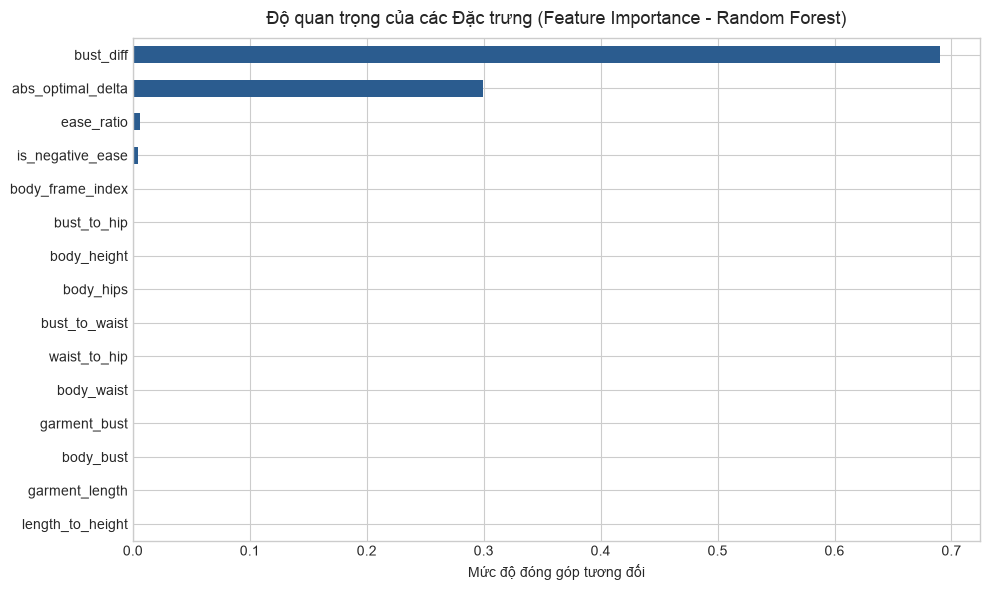

In [7]:
y_pred_score = rf_reg.predict(X_test)
mae = mean_absolute_error(y_test_score, y_pred_score)
rmse = np.sqrt(mean_squared_error(y_test_score, y_pred_score))
r2 = r2_score(y_test_score, y_pred_score)

print("=" * 60)
print("     KẾT QUẢ ĐÁNH GIÁ RANDOM FOREST TRÊN TẬP TEST ĐỘC LẬP     ")
print("=" * 60)
print(f"[*] HỒI QUY FIT SCORE:")
print(f"    - MAE            : {mae:.3f} điểm (Yêu cầu TC-AI-04: <= 5.0) -> {'ĐẠT XUẤT SẮC' if mae <= 5.0 else 'CHƯA ĐẠT'}")
print(f"    - RMSE           : {rmse:.3f} điểm")
print(f"    - R^2 Score      : {r2:.4f}")

y_pred_class = rf_clf.predict(X_test)
acc = accuracy_score(y_test_class, y_pred_class)
macro_f1 = f1_score(y_test_class, y_pred_class, average="macro")

print(f"\n[*] PHÂN LOẠI FIT CLASS:")
print(f"    - Accuracy       : {acc * 100:.2f}%")
print(f"    - Macro F1-Score : {macro_f1:.4f} (Yêu cầu TC-AI-04: >= 0.75) -> {'ĐẠT XUẤT SẮC' if macro_f1 >= 0.75 else 'CHƯA ĐẠT'}")

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test_class, y_pred_class, labels=FIT_CLASSES)
print(pd.DataFrame(cm, index=[f"True_{c}" for c in FIT_CLASSES], columns=[f"Pred_{c}" for c in FIT_CLASSES]))

importances = pd.Series(rf_reg.feature_importances_, index=FEATURE_COLS).sort_values(ascending=True)
plt.figure(figsize=(10, 6))
importances.plot(kind="barh", color="#2b5c8f")
plt.title("Độ quan trọng của các Đặc trưng (Feature Importance - Random Forest)", fontsize=13, pad=10)
plt.xlabel("Mức độ đóng góp tương đối")
plt.tight_layout()
plt.show()

## 6. Đóng gói & Lưu Model Weights để phục vụ Backend / API

In [8]:
weights_dir = PROJECT_ROOT / "ai" / "models" / "weights"
weights_dir.mkdir(parents=True, exist_ok=True)

model_bundle = {
    "regressor": rf_reg,
    "classifier": rf_clf,
    "feature_cols": FEATURE_COLS,
    "classes": FIT_CLASSES,
}

weight_path = weights_dir / "fit_predictor_rf.joblib"
joblib.dump(model_bundle, weight_path)
print(f"[+] Đã đóng gói và lưu mô hình thành công tại: {weight_path}")

def predict_single_sample(inputs: dict) -> dict:
    """Hàm suy luận 1 mẫu dành cho Backend FastAPI."""
    df_single = pd.DataFrame([inputs])
    df_feat = extract_fit_features(df_single)[FEATURE_COLS]
    
    score = float(rf_reg.predict(df_feat)[0])
    cls = str(rf_clf.predict(df_feat)[0])
    probs = rf_clf.predict_proba(df_feat)[0]
    conf = float(probs[list(rf_clf.classes_).index(cls)])
    
    return {
        "fit_score": round(score, 1),
        "classification": cls,
        "confidence": round(conf, 4),
        "method": "random_forest",
    }

sample_person_cloth = {
    "body_bust": 96.0,
    "body_height": 172.0,
    "body_hips": 98.0,
    "body_waist": 80.0,
    "garment_bust": 102.0,
    "garment_length": 68.0,
}
print("[*] Kết quả suy luận thời gian thực (Real-time Inference):")
print(predict_single_sample(sample_person_cloth))

[+] Đã đóng gói và lưu mô hình thành công tại: D:\Năm 4 - Kỳ 1\Project\virtual-tryon\virtual-try-on-platform\ai\models\weights\fit_predictor_rf.joblib
[*] Kết quả suy luận thời gian thực (Real-time Inference):
{'fit_score': 100.0, 'classification': 'Good', 'confidence': 1.0, 'method': 'random_forest'}
